In [1]:
import nflreadpy as nfl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pbp = nfl.load_pbp([2026])

In [3]:
df = pbp.to_pandas()

## General Dataset Anlysis

In [4]:
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (23647, 372)


,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
0,1.0,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,None,None,None,...,0.0,0.0,-0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,39.0,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0.0,0.0,0.291195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,62.0,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0.0,0.0,1.730269,0.402115,5.429666,3.0,1.0,1.000000,0.453482,54.651752
3,87.0,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0.0,0.0,-0.288451,NaN,NaN,NaN,NaN,NaN,0.402800,-40.280038
4,109.0,2026_01_ARI_LAC,2026091308,LAC,ARI,REG,1,ARI,away,LAC,...,0.0,0.0,-0.889568,0.361333,4.490768,2.0,1.0,0.998909,0.616770,38.322973


In [5]:
#Looking at different columns

df.columns.tolist()

['play_id',
 'game_id',
 'old_game_id',
 'home_team',
 'away_team',
 'season_type',
 'week',
 'posteam',
 'posteam_type',
 'defteam',
 'side_of_field',
 'yardline_100',
 'game_date',
 'quarter_seconds_remaining',
 'half_seconds_remaining',
 'game_seconds_remaining',
 'game_half',
 'quarter_end',
 'drive',
 'sp',
 'qtr',
 'down',
 'goal_to_go',
 'time',
 'yrdln',
 'ydstogo',
 'ydsnet',
 'desc',
 'play_type',
 'yards_gained',
 'shotgun',
 'no_huddle',
 'qb_dropback',
 'qb_kneel',
 'qb_spike',
 'qb_scramble',
 'pass_length',
 'pass_location',
 'air_yards',
 'yards_after_catch',
 'run_location',
 'run_gap',
 'field_goal_result',
 'kick_distance',
 'extra_point_result',
 'two_point_conv_result',
 'home_timeouts_remaining',
 'away_timeouts_remaining',
 'timeout',
 'timeout_team',
 'td_team',
 'td_player_name',
 'td_player_id',
 'posteam_timeouts_remaining',
 'defteam_timeouts_remaining',
 'total_home_score',
 'total_away_score',
 'posteam_score',
 'defteam_score',
 'score_differential',
 'po

In [6]:
#Finding the different play types and the amount of times they occured

df['play_type'].value_counts()

play_type
pass           9543
run            7074
no_play        2478
kickoff        1399
punt           1023
extra_point     618
field_goal      570
qb_kneel        201
qb_spike         50
Name: count, dtype: int64

In [7]:
#Using original datafram we found the average yards gained per play by play type

df.groupby('play_type')['yards_gained'].mean()

play_type
extra_point    0.000000
field_goal     0.000000
kickoff        0.000000
no_play        0.000000
pass           6.202976
punt           0.000000
qb_kneel      -1.144279
qb_spike       0.000000
run            4.332344
Name: yards_gained, dtype: float64

## Passing Play Analysis

In [8]:
#Creating a new dataframe of just pass plays

pass_plays = df[df['play_type'] == 'pass']

In [9]:
#Finding the average passing yards per play

str(round(pass_plays['yards_gained'].mean(), 2))

'6.2'

In [10]:
#Sorting the top 10 highest yards gained passing plays

pass_plays.sort_values(by = 'yards_gained', ascending = False).head(10)

,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
5509,503.0,2026_03_ARI_SF,2026092709,SF,ARI,REG,3,SF,home,ARI,...,0.0,0.0,7.660430,0.994348,3.805263,2.0,0.347572,0.200109,0.968367,3.163332
5173,178.0,2026_02_SEA_ARI,2026092010,ARI,SEA,REG,2,SEA,away,ARI,...,0.0,1.0,6.907721,0.825684,10.688336,5.0,1.000000,1.000000,0.600798,39.920169
1386,531.0,2026_01_GB_MIN,2026091310,MIN,GB,REG,1,GB,away,MIN,...,0.0,1.0,7.049448,0.371987,4.684528,2.0,1.000000,1.000000,0.518829,48.117059
12613,414.0,2026_05_IND_PIT,2026101105,PIT,IND,REG,5,PIT,home,IND,...,0.0,1.0,5.702825,0.782944,6.872151,6.0,0.578250,0.227173,0.511861,48.813862
4341,3614.0,2026_02_MIA_SF,2026092012,SF,MIA,REG,2,MIA,away,SF,...,0.0,0.0,7.010916,1.272485,12.779172,5.0,1.000000,1.000000,0.940648,5.935156
19083,3243.0,2026_08_ATL_TB,2026110107,TB,ATL,REG,8,ATL,away,TB,...,0.0,0.0,4.605727,0.465510,7.230537,3.0,1.000000,1.000000,0.707535,29.246527
20031,1780.0,2026_08_KC_DEN,2026110109,DEN,KC,REG,8,KC,away,DEN,...,0.0,0.0,7.018989,0.139762,3.666029,1.0,0.992024,0.951182,0.975872,2.412814
5807,3290.0,2026_03_ATL_GB,2026092400,GB,ATL,REG,3,ATL,away,GB,...,1.0,0.0,5.162955,0.612609,8.356286,4.0,1.000000,1.000000,0.724288,27.571213
2617,801.0,2026_01_WAS_PHI,2026091311,PHI,WAS,REG,1,PHI,home,WAS,...,0.0,0.0,4.174296,1.081391,12.300362,7.0,1.000000,1.000000,0.463226,53.677404
13772,2555.0,2026_05_TB_DAL,2026100800,DAL,TB,REG,5,TB,away,DAL,...,1.0,1.0,5.435248,0.569475,7.854295,4.0,1.000000,1.000000,0.805184,19.481635


In [11]:
#Total number of pass plays, incomplete and completed

len(pass_plays)

9543

In [12]:
#Only counting completed passes

len(pass_plays[pass_plays['complete_pass'] == 1])

5706

In [13]:
#Finding the amount of passing plays that resulted in a first down

len(pass_plays[pass_plays['first_down'] == 1])

3021

In [14]:
#Finding the total passing attempts/completed passes and getting the overall completion %

pass_attempts = len(pass_plays['pass_attempt'])
completed_passes = len(pass_plays[pass_plays['complete_pass'] == 1])

completion_percentage = (completed_passes / pass_attempts) * 100

print("The overall completion percentage up until the current week in the NFL is:", round(completion_percentage, 2))

The overall completion percentage up until the current week in the NFL is: 59.79


In [15]:
#Finding average yards per completed pass

round(pass_plays[pass_plays['complete_pass'] == 1]['yards_gained'].mean(), 2)

np.float64(11.07)

## Team Analysis

In [16]:
#Finding unique team abbreviations

df['posteam'].unique()

array([None, 'ARI', 'LAC', 'PIT', 'ATL', 'IND', 'BAL', 'BUF', 'HOU',
       'CHI', 'CAR', 'CLE', 'JAX', 'DAL', 'NYG', 'DEN', 'KC', 'MIN', 'GB',
       'MIA', 'LV', 'SEA', 'NE', 'DET', 'NO', 'NYJ', 'TEN', 'LA', 'SF',
       'TB', 'CIN', 'WAS', 'PHI'], dtype=object)

In [17]:
#Finding average yards gained by team

round(df.groupby('posteam')['yards_gained'].mean().sort_values(ascending = False),2)

posteam
SF     4.98
KC     4.93
BUF    4.83
CIN    4.71
NE     4.63
DET    4.53
JAX    4.47
LA     4.43
CHI    4.34
DAL    4.32
HOU    4.29
GB     4.28
ATL    4.24
CAR    4.23
LV     4.08
BAL    4.06
SEA    4.04
NYJ    4.01
PIT    4.00
WAS    3.94
NYG    3.90
MIA    3.80
NO     3.77
CLE    3.74
TB     3.72
TEN    3.71
MIN    3.64
ARI    3.62
DEN    3.53
LAC    3.52
IND    3.52
PHI    3.27
Name: yards_gained, dtype: float64

In [18]:
#Filtering to only show Kansas City

df[df['posteam'] == 'KC'].head()

,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
1209,126.0,2026_01_DEN_KC,2026091400,KC,DEN,REG,1,KC,home,DEN,...,0.0,0.0,-0.449889,NaN,NaN,NaN,NaN,NaN,0.436777,-43.677735
1210,148.0,2026_01_DEN_KC,2026091400,KC,DEN,REG,1,KC,home,DEN,...,0.0,0.0,-0.047746,NaN,NaN,NaN,NaN,NaN,0.678747,-67.874742
1211,170.0,2026_01_DEN_KC,2026091400,KC,DEN,REG,1,KC,home,DEN,...,0.0,0.0,-1.674052,NaN,NaN,NaN,NaN,NaN,0.847737,-84.773660
1212,192.0,2026_01_DEN_KC,2026091400,KC,DEN,REG,1,KC,home,DEN,...,0.0,0.0,2.773584,NaN,NaN,NaN,NaN,NaN,0.777337,-77.733690
1213,220.0,2026_01_DEN_KC,2026091400,KC,DEN,REG,1,KC,home,DEN,...,0.0,0.0,-0.509119,0.243511,3.162037,1.0,0.998908,0.471895,0.453168,54.683167


In [19]:
#Finding just Kansas City's average passing yards gained

kc_passing = df[(df['posteam'] == 'KC') & (df['play_type'] == 'pass')]

print("Kansas City's average passing yards gained is:", round(kc_passing['yards_gained'].mean(), 2))

Kansas City's average passing yards gained is: 7.17


In [20]:
#Finding which teams attmepted the most passes sorting from highest to lowest

df.groupby('posteam')['pass_attempt'].sum().sort_values(ascending = False)

posteam
ARI    382.0
LA     364.0
GB     359.0
DAL    353.0
CAR    341.0
LV     340.0
PHI    333.0
CHI    332.0
IND    329.0
NO     329.0
CLE    323.0
PIT    314.0
CIN    312.0
SEA    309.0
NE     303.0
HOU    302.0
DEN    302.0
NYJ    302.0
NYG    298.0
DET    293.0
WAS    288.0
LAC    275.0
ATL    275.0
KC     275.0
BAL    271.0
TB     267.0
TEN    263.0
SF     245.0
JAX    241.0
MIA    235.0
BUF    222.0
MIN    216.0
Name: pass_attempt, dtype: float64

In [21]:
pass_attempts = df.groupby('posteam')['pass_attempt'].sum()

In [22]:
#Finding the completion percentage for each team and ranking them from highest to lowest

pass_attempts = df.groupby('posteam')['pass_attempt'].sum()
completed_pass = df.groupby('posteam')['complete_pass'].sum()

total_team_comp_percentage = round((completed_pass / pass_attempts) * 100, 2).sort_values(ascending = False)

total_team_comp_percentage

posteam
CIN    70.19
SF     66.53
KC     64.36
LA     63.74
CHI    63.55
DET    63.48
NO     62.01
DAL    61.76
LV     61.47
JAX    61.00
BAL    60.89
BUF    60.81
ARI    60.73
NYJ    60.60
NE     60.40
HOU    60.26
GB     59.89
TEN    58.94
SEA    58.90
DEN    57.62
CLE    57.28
WAS    56.94
MIN    56.94
ATL    56.73
IND    55.93
PIT    55.73
CAR    55.43
NYG    55.37
TB     54.68
PHI    53.75
LAC    53.09
MIA    51.91
dtype: float64

In [23]:
#Finding the top 10 teams by total passing yards

df[df['play_type'] == 'pass'].groupby('posteam')['yards_gained'].sum().sort_values(ascending = False).head(10)

posteam
GB     2519.0
LV     2339.0
DAL    2314.0
LA     2290.0
CIN    2284.0
NE     2248.0
CHI    2169.0
HOU    2157.0
CAR    2089.0
DET    2016.0
Name: yards_gained, dtype: float64

In [24]:
#Finding the top 10 teams by average yards gained per pass play

pass_plays = df[df['play_type'] == 'pass']

passing_yards = pass_plays.groupby('posteam')['yards_gained'].sum()

passing_attempts = df.groupby('posteam')['pass_attempt'].sum()

yards_per_attempt = round(passing_yards / passing_attempts, 2).sort_values(ascending = False)

yards_per_attempt.head(10)

posteam
SF     7.89
BUF    7.73
JAX    7.61
NE     7.42
CIN    7.32
KC     7.17
HOU    7.14
GB     7.02
DET    6.88
LV     6.88
dtype: float64

In [25]:
#Finding total number of passing touchdowns by team

df.groupby('posteam')['pass_touchdown'].sum().sort_values(ascending = False)

posteam
CIN    23.0
LV     20.0
GB     19.0
NE     18.0
JAX    18.0
SF     17.0
LA     16.0
CAR    16.0
DAL    16.0
HOU    16.0
SEA    15.0
DET    15.0
KC     14.0
NO     14.0
PIT    13.0
ARI    13.0
NYG    12.0
NYJ    12.0
WAS    12.0
ATL    11.0
DEN    11.0
BUF    11.0
PHI    10.0
CHI    10.0
BAL    10.0
CLE     9.0
MIN     8.0
LAC     7.0
IND     6.0
MIA     6.0
TB      6.0
TEN     6.0
Name: pass_touchdown, dtype: float64

In [26]:
#Finding total interceptions by team

df.groupby('posteam')['interception'].sum().sort_values(ascending = False)

posteam
ATL    12.0
NE     11.0
LAC    11.0
IND    10.0
LA      9.0
TB      9.0
SEA     9.0
CHI     9.0
LV      8.0
ARI     7.0
CAR     6.0
CIN     6.0
PIT     6.0
PHI     6.0
NYG     6.0
NO      6.0
GB      6.0
MIA     6.0
BAL     5.0
DAL     5.0
TEN     5.0
BUF     5.0
SF      5.0
KC      4.0
JAX     4.0
DEN     4.0
CLE     3.0
MIN     3.0
NYJ     3.0
DET     2.0
HOU     2.0
WAS     1.0
Name: interception, dtype: float64

## QB Analysis

In [27]:
#Finding the top 10 total passing yards for each QB

pass_plays = df[df['play_type'] == 'pass']

pass_plays.groupby('passer_player_name')['yards_gained'].sum().sort_values(ascending = False).head(10)

passer_player_name
J.Love        2519.0
D.Prescott    2314.0
J.Burrow      2284.0
K.Cousins     2278.0
M.Stafford    2277.0
D.Maye        2181.0
C.Stroud      2150.0
B.Young       2042.0
J.Goff        2005.0
P.Mahomes     1971.0
Name: yards_gained, dtype: float64

In [28]:
#Calculating QB Completion Percentage with more then 10 total passing attempts

pass_plays = df[df['play_type'] == 'pass']

pass_completed_qb = pass_plays.groupby('passer_player_name')['complete_pass'].sum()

pass_attempt_qb = pass_plays.groupby('passer_player_name')['pass_attempt'].sum()
pass_attempt_qb_greater_10 = pass_attempt_qb[pass_attempt_qb > 10]

completion_percent = round((pass_completed_qb / pass_attempt_qb_greater_10) * 100, 2).sort_values(ascending = False).head(10)

completion_percent

passer_player_name
J.Dart        72.22
G.Minshew     70.37
J.Burrow      70.19
D.Lock        69.23
B.Purdy       67.08
L.Jackson     66.67
M.Stafford    64.43
P.Mahomes     64.36
C.Williams    64.11
C.Keenum      63.64
dtype: float64

In [29]:
#Calculating top 10 QB interception leaders

df.groupby('passer_player_name')['interception'].sum().sort_values(ascending = False).head(10)

passer_player_name
J.Herbert     11.0
D.Maye        11.0
D.Jones       10.0
S.Darnold      9.0
M.Stafford     9.0
K.Cousins      8.0
J.Brissett     7.0
T.Shough       6.0
A.Rodgers      6.0
B.Young        6.0
Name: interception, dtype: float64

In [30]:
#Calculating top 10 QB yards per attempt (minimum 100 attempts)

pass_plays = df[df['play_type'] == 'pass']

pass_attempt_qb = pass_plays.groupby('passer_player_name')['pass_attempt'].sum()
pass_attempt_qb_greater_100 = pass_attempt_qb[pass_attempt_qb > 100]

pass_yards_gained_qb = pass_plays.groupby('passer_player_name')['yards_gained'].sum()

total_pass_per_attempt_qb = round((pass_yards_gained_qb / pass_attempt_qb_greater_100), 2).sort_values(ascending = False).head(10)

total_pass_per_attempt_qb

passer_player_name
L.Jackson     8.85
B.Purdy       7.96
J.Allen       7.73
T.Lawrence    7.70
D.Maye        7.47
J.Burrow      7.32
C.Stroud      7.29
P.Mahomes     7.17
J.Love        7.02
K.Cousins     6.95
dtype: float64

## Creating QB Stats Table

In [31]:
#Creating a QB stats table

pass_plays = df[df['play_type'] == 'pass']

qb_stats = pass_plays.groupby('passer_player_name')['pass_attempt'].sum().reset_index()

qb_stats.head()

,passer_player_name,pass_attempt
0,A.Cole,1.0
1,A.Dalton,1.0
2,A.Kaliakmanis,34.0
3,A.Richardson,3.0
4,A.Rodgers,308.0


In [32]:
#Creating a new column of passing yards to add in, using map function to map the qb in the main table with the formula output

qb_stats['passing_yards'] = qb_stats['passer_player_name'].map(pass_plays.groupby('passer_player_name')['yards_gained'].sum())

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards
0,A.Cole,1.0,13.0
1,A.Dalton,1.0,0.0
2,A.Kaliakmanis,34.0,177.0
3,A.Richardson,3.0,-2.0
4,A.Rodgers,308.0,1684.0


In [33]:
#Adding in interceptions thrown by each QB

qb_stats['interceptions'] = qb_stats['passer_player_name'].map(pass_plays.groupby('passer_player_name')['interception'].sum())

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions
0,A.Cole,1.0,13.0,0.0
1,A.Dalton,1.0,0.0,1.0
2,A.Kaliakmanis,34.0,177.0,1.0
3,A.Richardson,3.0,-2.0,0.0
4,A.Rodgers,308.0,1684.0,6.0


In [34]:
#Adding completion percentage into the table

qb_stats['completions'] = qb_stats['passer_player_name'].map(pass_plays.groupby('passer_player_name')['complete_pass'].sum())

qb_stats['completion_pct'] = round((qb_stats['completions'] / qb_stats['pass_attempt']) * 100, 2)

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct
0,A.Cole,1.0,13.0,0.0,1.0,100.00
1,A.Dalton,1.0,0.0,1.0,0.0,0.00
2,A.Kaliakmanis,34.0,177.0,1.0,15.0,44.12
3,A.Richardson,3.0,-2.0,0.0,2.0,66.67
4,A.Rodgers,308.0,1684.0,6.0,175.0,56.82


In [35]:
#Adding yards per attempt into the table

qb_stats['yards_per_attempt'] = round(qb_stats['passing_yards'] / qb_stats['pass_attempt'], 2)

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt
0,A.Cole,1.0,13.0,0.0,1.0,100.00,13.00
1,A.Dalton,1.0,0.0,1.0,0.0,0.00,0.00
2,A.Kaliakmanis,34.0,177.0,1.0,15.0,44.12,5.21
3,A.Richardson,3.0,-2.0,0.0,2.0,66.67,-0.67
4,A.Rodgers,308.0,1684.0,6.0,175.0,56.82,5.47


In [36]:
#Creating new column of passing touchdowns

qb_stats['passing_tds'] = qb_stats['passer_player_name'].map(pass_plays.groupby('passer_player_name')['pass_touchdown'].sum())

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt,passing_tds
0,A.Cole,1.0,13.0,0.0,1.0,100.00,13.00,0.0
1,A.Dalton,1.0,0.0,1.0,0.0,0.00,0.00,0.0
2,A.Kaliakmanis,34.0,177.0,1.0,15.0,44.12,5.21,1.0
3,A.Richardson,3.0,-2.0,0.0,2.0,66.67,-0.67,0.0
4,A.Rodgers,308.0,1684.0,6.0,175.0,56.82,5.47,13.0


In [37]:
#Creating TD percentage, how likely a QB is to throw a TD based on passing attempts (NOT completed passes)

qb_stats['td_percentage'] = round((qb_stats['passing_tds'] / qb_stats['pass_attempt']) * 100, 2)

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt,passing_tds,td_percentage
0,A.Cole,1.0,13.0,0.0,1.0,100.00,13.00,0.0,0.00
1,A.Dalton,1.0,0.0,1.0,0.0,0.00,0.00,0.0,0.00
2,A.Kaliakmanis,34.0,177.0,1.0,15.0,44.12,5.21,1.0,2.94
3,A.Richardson,3.0,-2.0,0.0,2.0,66.67,-0.67,0.0,0.00
4,A.Rodgers,308.0,1684.0,6.0,175.0,56.82,5.47,13.0,4.22


In [38]:
#Creating interception percentage based on passing attempts

qb_stats['int_percentage'] = round((qb_stats['interceptions'] / qb_stats['pass_attempt']) * 100, 2)

qb_stats.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt,passing_tds,td_percentage,int_percentage
0,A.Cole,1.0,13.0,0.0,1.0,100.00,13.00,0.0,0.00,0.00
1,A.Dalton,1.0,0.0,1.0,0.0,0.00,0.00,0.0,0.00,100.00
2,A.Kaliakmanis,34.0,177.0,1.0,15.0,44.12,5.21,1.0,2.94,2.94
3,A.Richardson,3.0,-2.0,0.0,2.0,66.67,-0.67,0.0,0.00,0.00
4,A.Rodgers,308.0,1684.0,6.0,175.0,56.82,5.47,13.0,4.22,1.95


In [39]:
#Sorting QB stats to see who has the most passing ayrds

qb_stats.sort_values(by = 'passing_yards', ascending = False).head(10)

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt,passing_tds,td_percentage,int_percentage
41,J.Love,359.0,2519.0,6.0,215.0,59.89,7.02,19.0,5.29,1.67
24,D.Prescott,353.0,2314.0,5.0,218.0,61.76,6.56,16.0,4.53,1.42
33,J.Burrow,312.0,2284.0,6.0,219.0,70.19,7.32,23.0,7.37,1.92
47,K.Cousins,328.0,2278.0,8.0,202.0,61.59,6.95,20.0,6.10,2.44
55,M.Stafford,357.0,2277.0,9.0,230.0,64.43,6.38,16.0,4.48,2.52
22,D.Maye,292.0,2181.0,11.0,178.0,60.96,7.47,18.0,6.16,3.77
14,C.Stroud,295.0,2150.0,2.0,181.0,61.36,7.29,16.0,5.42,0.68
10,B.Young,334.0,2042.0,6.0,186.0,55.69,6.11,16.0,4.79,1.80
38,J.Goff,292.0,2005.0,2.0,185.0,63.36,6.87,15.0,5.14,0.68
58,P.Mahomes,275.0,1971.0,4.0,177.0,64.36,7.17,14.0,5.09,1.45


## Visualizing QB Data

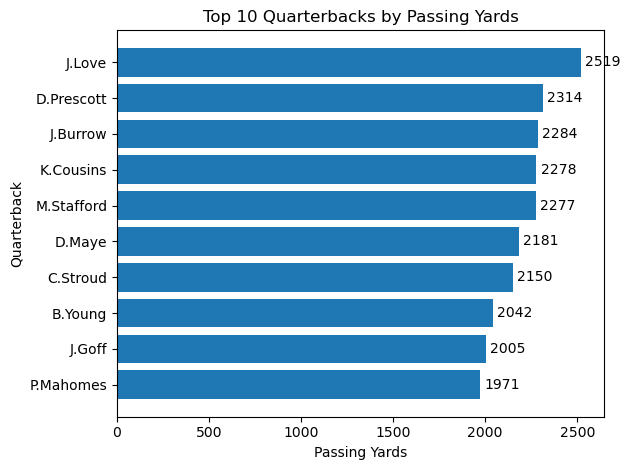

In [40]:
#Visualizing top 10 QBs by passing yards bar chart

top_10_qbs = qb_stats.sort_values(by = 'passing_yards', ascending = False).head(10)

bars = plt.barh(top_10_qbs['passer_player_name'],
         top_10_qbs['passing_yards'],
        color = 'tab:blue')

plt.title('Top 10 Quarterbacks by Passing Yards')
plt.xlabel('Passing Yards')
plt.ylabel('Quarterback')
plt.bar_label(bars, padding = 3)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [41]:
#Want to first filter out and only show QBs with 150+ passing yards minimum

qb_yards_filtered = qb_stats[qb_stats['passing_yards'] > 150]

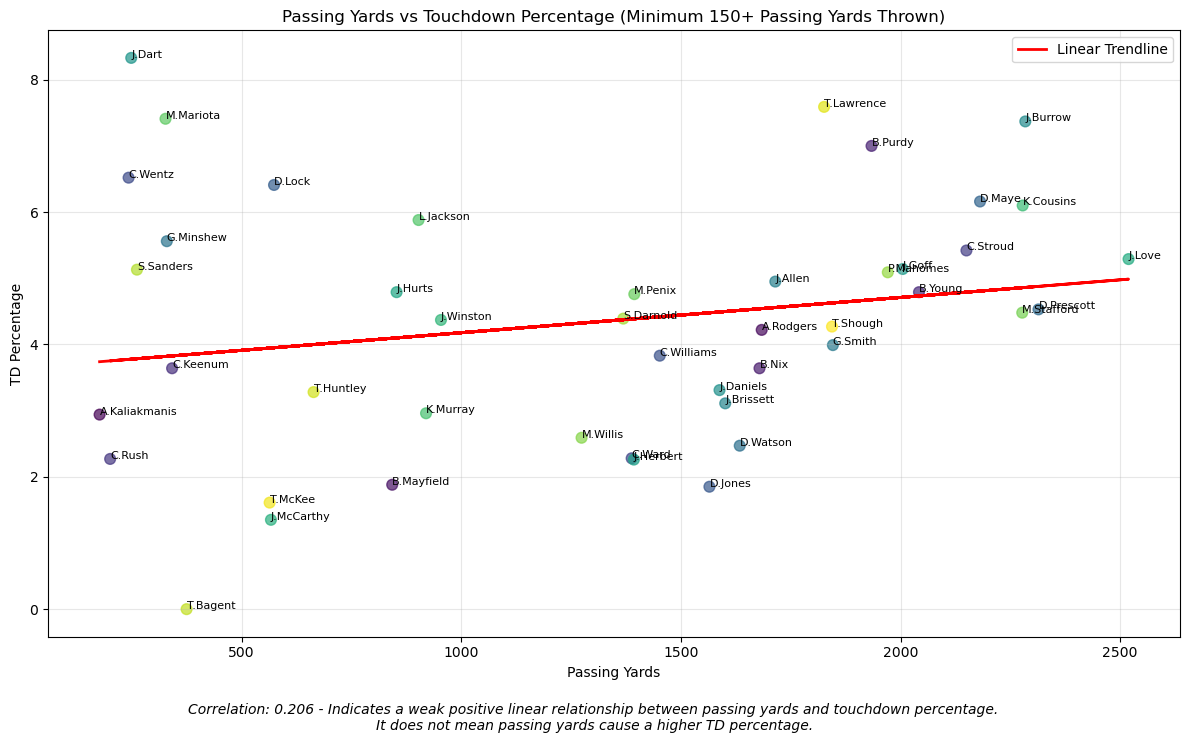

In [42]:
#Creating scatter plot to compare passing yards against touchdown percentage

#Calculating the correlation

qb_corr = round(qb_yards_filtered['passing_yards'].corr(qb_yards_filtered['td_percentage']), 3)

#Creating Trendline
x = qb_yards_filtered['passing_yards']
y = qb_yards_filtered['td_percentage']
coefficients = np.polyfit(x, y, 1)
trendline = np.poly1d(coefficients)

#Scatter Plot
plt.figure(figsize = (12, 7))
plt.scatter(qb_yards_filtered['passing_yards'], qb_yards_filtered['td_percentage'], c = range(len(qb_yards_filtered)), cmap = 'viridis', s = 60, alpha = 0.7)

#This creates the QB annotation for each circle
for index, row in qb_yards_filtered.iterrows():
    plt.annotate(
        row['passer_player_name'],
        (row['passing_yards'], row['td_percentage']), fontsize = 8)

#General Scatterplot descriptions
plt.title('Passing Yards vs Touchdown Percentage (Minimum 150+ Passing Yards Thrown)')
plt.xlabel('Passing Yards')
plt.ylabel('TD Percentage')

#This creates the trendline
plt.plot(x, trendline(x), color = 'red', linewidth = 2, label = 'Linear Trendline')

#Adding an annocation at the bottom to explain the correlation
plt.figtext(
    0.5, -0.05,
    f'Correlation: {qb_corr:.3f} - Indicates a weak positive linear relationship between passing yards and touchdown percentage. \nIt does not mean passing yards cause a higher TD percentage.',
    ha = 'center',
    fontsize = 10,
    style = 'italic')

plt.tight_layout()
plt.grid(True, alpha = 0.3)
plt.legend()
plt.show()

## QB Touchdown Percentage Analysis

In [43]:
#Creating a new Dataframe with the respected columns below and then sorting the highest td_percentages only showing top 10

top_10_td_pct = qb_yards_filtered[['passer_player_name', 'pass_attempt', 'passing_tds', 'td_percentage']]

top_10_td_pct = top_10_td_pct.sort_values(by = 'td_percentage', ascending = False).head(10)
top_10_td_pct

,passer_player_name,pass_attempt,passing_tds,td_percentage
35,J.Dart,36.0,3.0,8.33
67,T.Lawrence,237.0,18.0,7.59
52,M.Mariota,54.0,4.0,7.41
33,J.Burrow,312.0,23.0,7.37
9,B.Purdy,243.0,17.0,7.00
16,C.Wentz,46.0,3.0,6.52
21,D.Lock,78.0,5.0,6.41
22,D.Maye,292.0,18.0,6.16
47,K.Cousins,328.0,20.0,6.10
51,L.Jackson,102.0,6.0,5.88


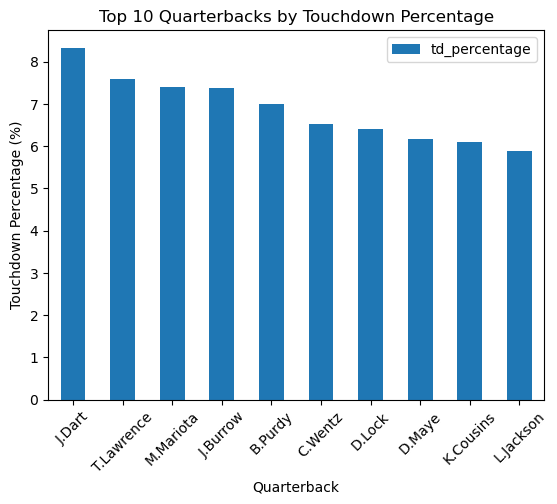

In [44]:
# Creating a bar chart to help visualize the top 10 QBs by TD Percentage

top_10_td_pct.plot(x = 'passer_player_name', y = 'td_percentage', kind = 'bar', title = 'Top 10 Quarterbacks by Touchdown Percentage')
plt.xlabel('Quarterback')
plt.ylabel('Touchdown Percentage (%)')
plt.xticks(rotation = 45)
plt.show()

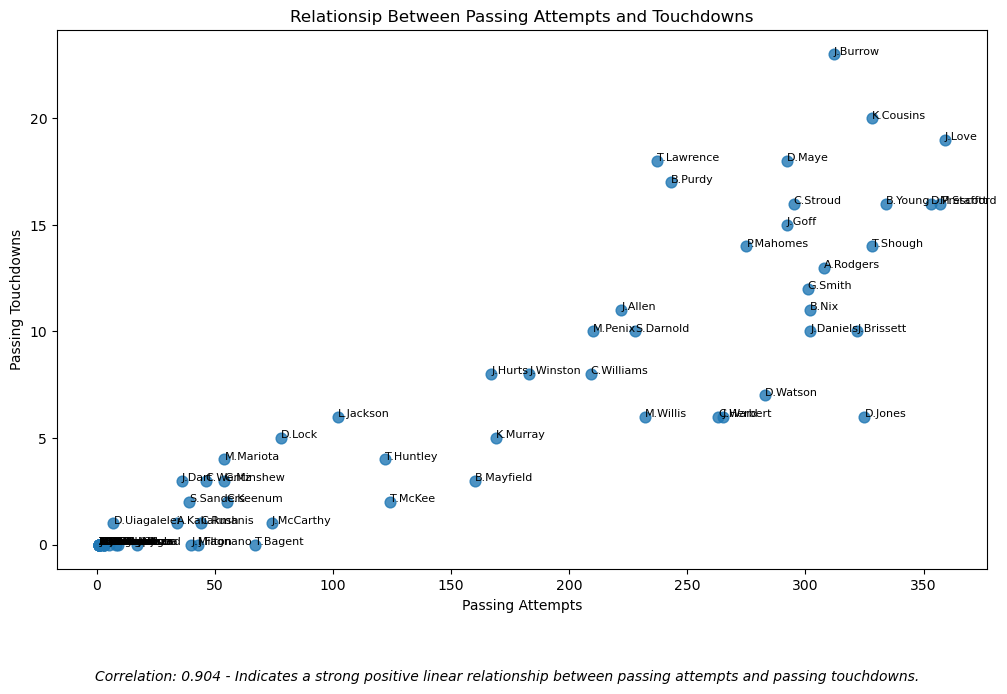

In [45]:
#Analyzing relationship between passing attempts and touchdowns

#Calcualting Correlation
qb_corr_attempts = round(qb_stats['pass_attempt'].corr(qb_stats['passing_tds']), 3)

plt.figure(figsize= (12,7))
plt.scatter(qb_stats['pass_attempt'], qb_stats['passing_tds'], s = 60, alpha = 0.8)

for index, row in qb_stats.iterrows():
    plt.annotate(
        row['passer_player_name'],
        (row['pass_attempt'], row['passing_tds']), fontsize = 8)

plt.title('Relationsip Between Passing Attempts and Touchdowns')
plt.xlabel('Passing Attempts')
plt.ylabel('Passing Touchdowns')

#Adding an annocation at the bottom to explain the correlation
plt.figtext(
    0.5, -0.05,
    f'Correlation: {qb_corr_attempts:.3f} - Indicates a strong positive linear relationship between passing attempts and passing touchdowns.',
    ha = 'center',
    fontsize = 10,
    style = 'italic')

plt.show()

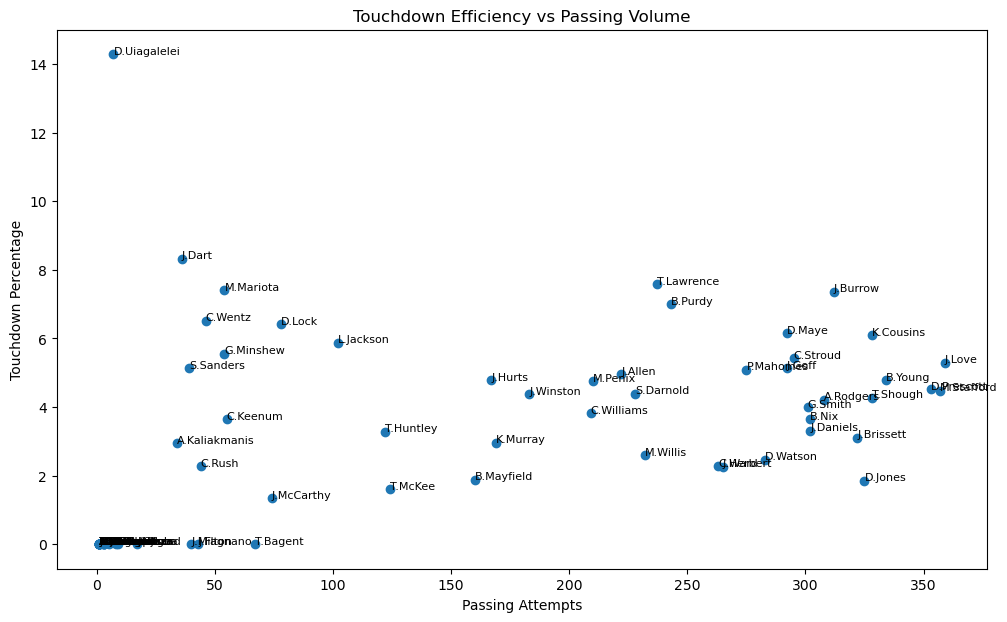

In [46]:
#Calculating Touchdown Efficiency vs Passing Volume
#we want to investigate whether quarterbacks who throw more frequently are actually more efficient at producing touchdowns

plt.figure(figsize = (12,7))
plt.scatter(qb_stats['pass_attempt'], qb_stats['td_percentage'])

#Adding annotations in

for index, row in qb_stats.iterrows():
    plt.annotate(
        row['passer_player_name'],
        (row['pass_attempt'], row['td_percentage']), fontsize = 8)

plt.title('Touchdown Efficiency vs Passing Volume')
plt.xlabel('Passing Attempts')
plt.ylabel('Touchdown Percentage')
plt.show()

In [47]:
#Calculating Correlation

correlation = np.corrcoef(qb_stats['pass_attempt'], qb_stats['td_percentage'])
correlation[0, 1]

np.float64(0.4913470915255716)

In [48]:
#Investigating Correlation

#Creating a new dataframe with only the three columns
qb_eff_sorted = qb_stats[['passer_player_name', 'pass_attempt', 'td_percentage']]

#Sorting the dataframe by pass_attempt in descending order
qb_eff_sorted.sort_values(by = 'pass_attempt', ascending = False).head(10)

#Can see that throwing it more doesnt really mean there more efficient percent wise

,passer_player_name,pass_attempt,td_percentage
41,J.Love,359.0,5.29
55,M.Stafford,357.0,4.48
24,D.Prescott,353.0,4.53
10,B.Young,334.0,4.79
69,T.Shough,328.0,4.27
47,K.Cousins,328.0,6.10
20,D.Jones,325.0,1.85
32,J.Brissett,322.0,3.11
33,J.Burrow,312.0,7.37
4,A.Rodgers,308.0,4.22


In [49]:
#Sorting the dataframe by pass_attempt in descending order
qb_eff_sorted.sort_values(by = 'pass_attempt', ascending = True).head(10)

#We can see without filtering out the Quarterbacks with low passing attempts it skews our data and correlation

,passer_player_name,pass_attempt,td_percentage
0,A.Cole,1.0,0.0
65,T.Harris,1.0,0.0
57,Mi.Wilson,1.0,0.0
54,M.Rudolph,1.0,0.0
48,K.Kroeger,1.0,0.0
44,J.Smith-Njigba,1.0,0.0
37,J.Fox,1.0,0.0
27,E.Chism,1.0,0.0
19,D.Henry,1.0,0.0
18,D.Brown,1.0,0.0


In [50]:
#Filtering out the low volume Quarterbacks

qb_min_attempts = qb_stats[qb_stats['pass_attempt'] >= 100]
qb_min_attempts.head()

,passer_player_name,pass_attempt,passing_yards,interceptions,completions,completion_pct,yards_per_attempt,passing_tds,td_percentage,int_percentage
4,A.Rodgers,308.0,1684.0,6.0,175.0,56.82,5.47,13.0,4.22,1.95
6,B.Mayfield,160.0,843.0,4.0,86.0,53.75,5.27,3.0,1.88,2.50
7,B.Nix,302.0,1679.0,4.0,174.0,57.62,5.56,11.0,3.64,1.32
9,B.Purdy,243.0,1934.0,5.0,163.0,67.08,7.96,17.0,7.00,2.06
10,B.Young,334.0,2042.0,6.0,186.0,55.69,6.11,16.0,4.79,1.80


In [51]:
#Finding the shape of the new filtered dataframe to find how many QBs remain (33)

qb_min_attempts.shape

(34, 10)

In [52]:
correlation_filtered = np.corrcoef(qb_min_attempts['pass_attempt'], qb_min_attempts['td_percentage'])
correlation_value = correlation_filtered[0,1]

#Relationship we observed in the full dataset becomes almost nonexistent when we restrict the analysis to quarterbacks with at least 100 attempts.
#Suggests the low-volume quarterbacks may have been influencing the original correlation

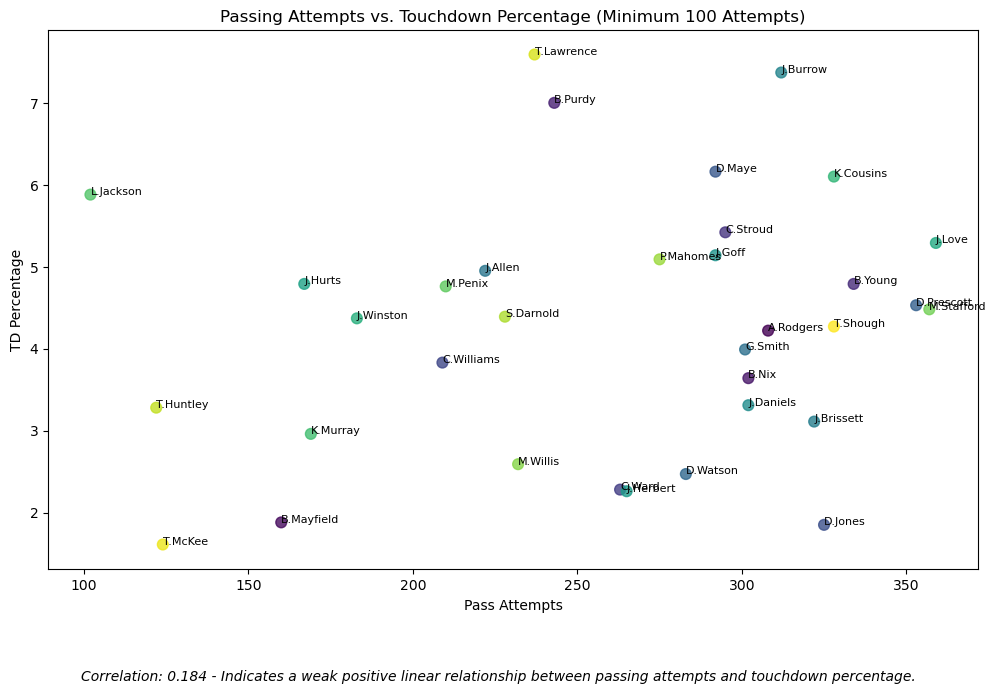

In [53]:
#Lets visualize the above correlation to get a better understanding of there being no correlation

plt.figure(figsize = (12,7))
plt.scatter(qb_min_attempts['pass_attempt'], qb_min_attempts['td_percentage'], c = range(len(qb_min_attempts)), cmap = 'viridis', s = 60, alpha = 0.8)

for index, row in qb_min_attempts.iterrows():
    plt.annotate(
        row['passer_player_name'],
        (row['pass_attempt'], row['td_percentage']), fontsize = 8)
    
plt.figtext(
    0.5, -0.05,
    f'Correlation: {correlation_value:.3f} - Indicates a weak positive linear relationship between passing attempts and touchdown percentage.',
    ha = 'center',
    fontsize = 10,
    style = 'italic')

plt.title('Passing Attempts vs. Touchdown Percentage (Minimum 100 Attempts)')
plt.xlabel('Pass Attempts')
plt.ylabel('TD Percentage')
plt.show()